## Cbi dữ liệu

In [1]:
import numpy as np
import joblib
import matplotlib.pyplot as plt

In [39]:
data = joblib.load("mnist_data.pkl")

X_train, y_train, X_test, y_test = data

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

X_train shape: (60000, 28, 28, 1)
y_train shape: (60000,)
X_test shape : (10000, 28, 28, 1)
y_test shape : (10000,)


# Huấn luyện

## Công thức

In [40]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

In [41]:
from numpy.lib.stride_tricks import sliding_window_view

def conv2d_forward(X, K, b):
    batch_size, height, width, channels = X.shape
    num_filters, kernel_h, kernel_w, _ = K.shape

    # Tạo các cửa sổ trượt
    windows = sliding_window_view(
        X, (kernel_h, kernel_w), axis=(1, 2)
    )

    # (N, OH, OW, KH, KW, C)
    windows = windows.transpose(0, 1, 2, 4, 5, 3)

    # Tích chập cho toàn bộ batch và filters
    Z = np.einsum(
        "nijhwc,fhwc->nijf",
        windows, K,
        optimize=True
    )

    Z += b[None, None, None, :]

    return Z

In [42]:
def conv2d_backward(X, K, b, dZ):
    batch_size, height, width, channels = X.shape
    num_filters, kernel_h, kernel_w, _ = K.shape

    output_height, output_width = dZ.shape[1:3]

    # Các cửa sổ đầu vào
    windows = sliding_window_view(
        X, (kernel_h, kernel_w), axis=(1, 2)
    )
    windows = windows.transpose(0, 1, 2, 4, 5, 3)

    # Gradient của kernel
    dK = np.einsum(
        "nijhwc,nijf->fhwc",
        windows, dZ,
        optimize=True
    )

    # Gradient của bias
    db = np.sum(dZ, axis=(0, 1, 2))

    # Gradient của đầu vào
    dX = np.zeros_like(X)

    # Chỉ lặp theo vị trí kernel, không lặp theo từng pixel
    for i in range(kernel_h):
        for j in range(kernel_w):
            dX[
                :, i:i + output_height,
                j:j + output_width, :
            ] += np.einsum(
                "nijf,fc->nijc",
                dZ, K[:, i, j, :],
                optimize=True
            )

    return dX, dK, db

In [43]:
def max_pool2d_forward(X, pool_size=2, stride=2):
    windows = sliding_window_view(
        X, (pool_size, pool_size), axis=(1, 2)
    )

    # Lấy các cửa sổ cách nhau stride pixel
    windows = windows[:, ::stride, ::stride, :, :, :]

    # (N, OH, OW, pool_h, pool_w, C)
    windows = windows.transpose(0, 1, 2, 4, 5, 3)

    return np.max(windows, axis=(3, 4))

In [44]:
def max_pool2d_backward(X, dP, pool_size=2, stride=2):
    batch_size, height, width, channels = X.shape
    output_height, output_width = dP.shape[1:3]

    windows = sliding_window_view(
        X, (pool_size, pool_size), axis=(1, 2)
    )
    windows = windows[:, ::stride, ::stride, :, :, :]
    windows = windows.transpose(0, 1, 2, 4, 5, 3)

    # Giá trị cực đại theo từng channel
    max_values = np.max(
        windows, axis=(3, 4), keepdims=True
    )

    # Vị trí đạt cực đại
    mask = (windows == max_values)

    dX = np.zeros_like(X)

    # Chỉ lặp theo các vị trí trong cửa sổ pooling
    for i in range(pool_size):
        for j in range(pool_size):
            dX[
                :,
                i:i + output_height * stride:stride,
                j:j + output_width * stride:stride,
                :
            ] += (
                mask[:, :, :, i, j, :]
                * dP
            )

    return dX

In [45]:
def forward(X):
    
    # ===== Conv 1 =====
    Z1 = conv2d_forward(X, K1, b1)
    H1 = relu(Z1)
    P1 = max_pool2d_forward(H1)

    # ===== Conv 2 =====
    Z2 = conv2d_forward(P1, K2, b2)
    H2 = relu(Z2)
    P2 = max_pool2d_forward(H2)

    # ===== Flatten =====
    flat = P2.reshape(P2.shape[0], -1)

    # ===== Fully Connected =====
    Z3 = flat @ W3 + b3
    H3 = relu(Z3)

    # ===== Output =====
    Z4 = H3 @ W4 + b4
    Y_hat = softmax(Z4)

    cache = (
        Z1, H1, P1,
        Z2, H2, P2,
        flat,
        Z3, H3,
        Z4
    )

    return Y_hat, cache

In [46]:
def cross_entropy(y, y_hat):
    eps = 1e-8
    y_hat = np.clip(y_hat, eps, 1 - eps)

    batch_size = y.shape[0]

    loss = -np.mean(
        np.log(
            y_hat[np.arange(batch_size), y]
        )
    )

    return loss

In [47]:
def backward(X, y, y_hat, cache):
    (
        Z1, H1, P1,
        Z2, H2, P2,
        flat,
        Z3, H3,
        Z4
    ) = cache

    batch_size = X.shape[0]

    # =========================
    # Output + Softmax + CE
    # =========================

    dZ4 = y_hat.copy()
    dZ4[np.arange(batch_size), y] -= 1
    dZ4 /= batch_size

    dW4 = H3.T @ dZ4
    db4 = np.sum(dZ4, axis=0, keepdims=True)

    dH3 = dZ4 @ W4.T

    # =========================
    # ReLU
    dZ3 = (dH3 * relu_derivative(Z3))
    # Dense
    dW3 = flat.T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)
    dflat = dZ3 @ W3.T
    # Flatten
    dP2 = dflat.reshape(P2.shape)
    # =========================

    # =========================
    # Pool 2
    dH2 = max_pool2d_backward(H2, dP2)
    # ReLU
    dZ2 = (dH2 * relu_derivative(Z2))
    # Conv 2
    dP1, dK2, db2 = conv2d_backward(P1, K2, b2, dZ2)
    # =========================

    # =========================
    # Pool 1
    dH1 = max_pool2d_backward(H1, dP1)
    # ReLU
    dZ1 = (dH1 * relu_derivative(Z1))
    # Conv 1
    dX, dK1, db1 = conv2d_backward(X, K1, b1, dZ1)
    # =========================
    
    grads = {
        "dK1": dK1, "db1": db1,
        "dK2": dK2, "db2": db2,
        "dW3": dW3, "db3": db3,
        "dW4": dW4, "db4": db4
    }

    return grads

In [48]:
def update(grads, learning_rate):
    global K1, b1, K2, b2, W3, b3, W4, b4

    K1 -= learning_rate * grads["dK1"]
    b1 -= learning_rate * grads["db1"]

    K2 -= learning_rate * grads["dK2"]
    b2 -= learning_rate * grads["db2"]

    W3 -= learning_rate * grads["dW3"]
    b3 -= learning_rate * grads["db3"]

    W4 -= learning_rate * grads["dW4"]
    b4 -= learning_rate * grads["db4"]

In [49]:
def softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)

    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

## Thực nghiệm

### Khởi tạo tham số

In [50]:
np.random.seed(42)

num_filters_1 = 8
kernel_size_1 = 3
input_channels = 1

K1 = np.random.randn(
    num_filters_1,
    kernel_size_1,
    kernel_size_1,
    input_channels
) * 0.01

b1 = np.zeros(num_filters_1)

In [51]:
num_filters_2 = 8
kernel_size_2 = 3

K2 = np.random.randn(
    num_filters_2,
    kernel_size_2,
    kernel_size_2,
    num_filters_1
) * 0.01

b2 = np.zeros(num_filters_2)

In [52]:
hidden_size = 16
num_classes = 10

flatten_size = 5 * 5 * num_filters_2

W3 = np.random.randn(flatten_size,hidden_size) * 0.01
b3 = np.zeros((1, hidden_size))

W4 = np.random.randn(hidden_size,num_classes) * 0.01
b4 = np.zeros((1, num_classes))

print("Flatten size:", flatten_size)
print("W3 shape:", W3.shape)
print("W4 shape:", W4.shape)

Flatten size: 200
W3 shape: (200, 16)
W4 shape: (16, 10)


### Lặp

In [ ]:
epochs = 10
learning_rate = 0.01
batch_size = 256

losses = []

for epoch in range(epochs):
    permutation = np.random.permutation(len(X_train))

    total_loss = 0
    num_batches = 0

    for i in range(0,len(X_train),batch_size):
        idx = permutation[i:i + batch_size]

        X_batch = X_train[idx]
        y_batch = y_train[idx]

        # Forward
        y_hat, cache = forward(X_batch)

        # Loss
        loss = cross_entropy(y_batch,y_hat)

        # Backward
        grads = backward(
            X_batch, y_batch,
            y_hat, cache
        )

        # Update
        update(grads, learning_rate)

        total_loss += loss
        num_batches += 1

    avg_loss = (total_loss / num_batches)

    losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{epochs}"
        f" - Loss: {avg_loss:.4f}"
    )

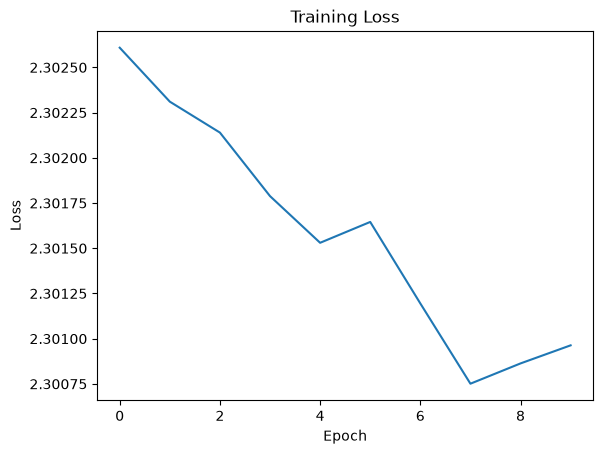

In [ ]:
plt.plot(losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

# Kết quả

In [ ]:
y_prob, _ = forward(X_test)

y_pred = np.argmax(
    y_prob,
    axis=1
)

print("y_prob shape:", y_prob.shape)
print("y_pred shape:", y_pred.shape)

y_prob shape: (10000, 10)
y_pred shape: (10000,)


In [ ]:
accuracy = np.mean(
    y_pred == y_test
)

print("Accuracy:", accuracy)

Accuracy: 0.0974


In [ ]:
confusion_matrix = np.zeros(
    (10, 10),
    dtype=int
)

for true, pred in zip(
    y_test,
    y_pred
):
    confusion_matrix[
        true,
        pred
    ] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[   0    0    0    0    0    0    0    0  980    0]
 [   0    0    0    0    0    0    0    0 1135    0]
 [   0    0    0    0    0    0    0    0 1032    0]
 [   0    0    0    0    0    0    0    0 1010    0]
 [   0    0    0    0    0    0    0    0  982    0]
 [   0    0    0    0    0    0    0    0  892    0]
 [   0    0    0    0    0    0    0    0  958    0]
 [   0    0    0    0    0    0    0    0 1028    0]
 [   0    0    0    0    0    0    0    0  974    0]
 [   0    0    0    0    0    0    0    0 1009    0]]


In [ ]:
precisions = []
recalls = []
f1_scores = []

for c in range(10):

    TP = confusion_matrix[c, c]

    FP = (
        np.sum(confusion_matrix[:, c])
        - TP
    )

    FN = (
        np.sum(confusion_matrix[c, :])
        - TP
    )

    precision = (
        TP / (TP + FP + 1e-8)
    )

    recall = (
        TP / (TP + FN + 1e-8)
    )

    f1 = (
        2 * precision * recall
        / (precision + recall + 1e-8)
    )

    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)

precision_macro = np.mean(
    precisions
)

recall_macro = np.mean(
    recalls
)

f1_macro = np.mean(
    f1_scores
)

print("Accuracy :", accuracy)
print("Precision:", precision_macro)
print("Recall   :", recall_macro)
print("F1-score :", f1_macro)

Accuracy : 0.0974
Precision: 0.00973999999999026
Recall   : 0.09999999999897331
F1-score : 0.01775104776968655


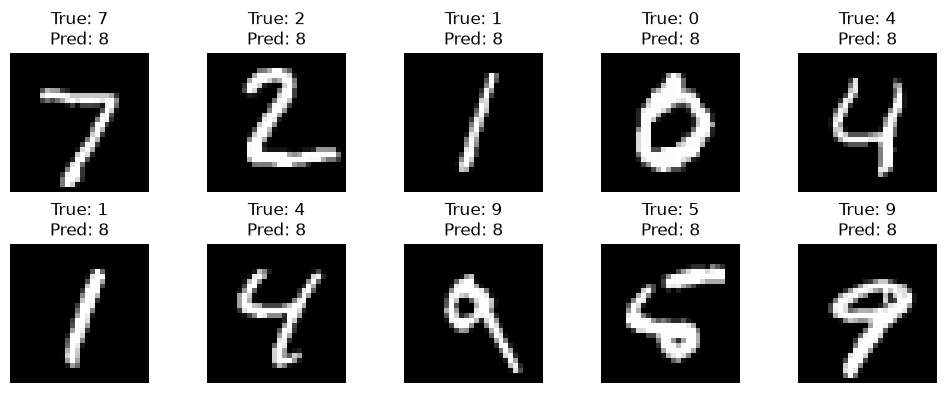

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"True: {y_test[i]}\n"
        f"Pred: {y_pred[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Xuất kết quả

In [ ]:
joblib.dump(
    {
        "Model": "CNN From Scratch",
        "Accuracy": accuracy,
        "Precision": precision_macro,
        "Recall": recall_macro,
        "F1-score": f1_macro,
        "Confusion Matrix": confusion_matrix
    },
    "cnn_result.pkl"
)

['cnn_result.pkl']